# 5.3 การเปรียบเทียบแผนและทางเลือกนโยบาย

ทุกแผนถูกประเมินด้วยทุกตัวหาร (ประชากร ทะเบียนสิทธิ บริการ บริการคาดหมายมาตรฐาน M5 และบริการที่ตอบสนองทรัพยากร)
ความต่างถูกแปลเป็นจำนวนแพทย์ที่ต้องเปลี่ยนจังหวัดปลายทาง จังหวัด และปี เกณฑ์ "ใกล้เคียงเชิงปฏิบัติ" ถูกกำหนดใน config ก่อนอ่านผล

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "chapter5.toml").exists())
sys.path.insert(0, str(_root / "src"))
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
pd.options.display.max_columns = 40
pd.options.display.width = 200
from chapter5 import config as C, pipeline as PL, allocation as AL, simulation as SIM, responsibilities as R
S = C.load()
D = S.dirs()
tab = lambda n, f="tables": pd.read_csv(D[f] / f"{n}.csv", encoding="utf-8-sig")
print("scenario:", S.name, "| config_hash:", S.hash())

scenario: canonical | config_hash: e0082b9acf0428bc


In [2]:
print(json.dumps(S.cfg['evaluation'], ensure_ascii=False, indent=1))
display(tab('T53_MAIN_PLANS'))

{
 "plan_modes": [
  "fixed_schedule",
  "annual_replanning"
 ],
 "paired_random_paths": true,
 "main_simulation_runs": 500,
 "dev_simulation_runs": 40,
 "adaptive_simulation_runs": 60,
 "switch_threshold_pct": 5.0,
 "cumulative_shortfall_threshold_pct": 2.0,
 "worst_province_loss_threshold_pct": 5.0,
 "bottom_quartile": 19
}


,แผน,ตัวหาร,การโยกย้าย,เป้าหมาย,สถานะ,แพทย์ 2583,ความเพียงพอรวม 2583,กลุ่มล่าง 19 จังหวัด 2583,ต่ำสุด 2583,Gini 2583,การโยกย้ายสะสม (ครั้ง),สัดส่วนจังหวัด-ปีที่เพดานตึง
0,P-R,ประชากร,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30011,0.542,0.377,0.099,0.083,0,0.63
1,P-RT,ประชากร,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30011,0.542,0.377,0.099,0.083,0,0.63
2,S-R,บริการที่เกิดขึ้น,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,29948,0.541,0.416,0.120,0.057,0,0.62
3,S-RT,บริการที่เกิดขึ้น,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,29948,0.541,0.416,0.120,0.057,0,0.62
4,N-R,บริการคาดหมายมาตรฐาน M5,ไม่มี,"รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30010,0.542,0.395,0.096,0.074,0,0.63
5,N-RT,บริการคาดหมายมาตรฐาน M5,"มี (≤2%/ปี, งบประเทศ 1%)","รวมร่วม 1:1,000 (Experiment A)",exploratory_policy_scenario,30010,0.542,0.395,0.096,0.074,0,0.63


In [3]:
display(tab('T56_CROSS_EVALUATION'))
xe = tab('T5_CROSS_EVALUATION_LONG')
display(xe[xe.plan_id.isin(['P-R', 'S-R', 'N-R'])].pivot_table(index='plan_id', columns='criterion', values=['bottom_quartile_2040', 'regret_j_pct']).round(3))

,แผน,บริการคาดหมายมาตรฐาน M5,ประชากรทะเบียนราษฎร,ประชากรทะเบียนสิทธิ,บริการที่เกิดขึ้น,DALY คาดหมาย,บริการตอบสนองทรัพยากร λ=1
0,P-R,0.395 / +0.1%,0.377 / +0.0%,0.381 / +0.1%,0.392 / +1.3%,0.392 / +0.9%,0.421 (Gini 0.089)
1,P-RT,0.395 / +0.1%,0.377 / +0.0%,0.381 / +0.1%,0.392 / +1.3%,0.392 / +0.9%,0.421 (Gini 0.089)
2,S-R,0.368 / +1.6%,0.351 / +1.9%,0.358 / +1.8%,0.416 / +0.0%,0.377 / +2.1%,0.432 (Gini 0.059)
3,S-RT,0.368 / +1.6%,0.351 / +1.9%,0.358 / +1.8%,0.416 / +0.0%,0.377 / +2.1%,0.432 (Gini 0.059)
4,N-R,0.395 / +0.0%,0.377 / +0.1%,0.386 / +0.2%,0.397 / +1.1%,0.397 / +0.7%,0.429 (Gini 0.086)
5,N-RT,0.395 / +0.0%,0.377 / +0.1%,0.386 / +0.2%,0.397 / +1.1%,0.397 / +0.7%,0.429 (Gini 0.086)
6,SQ-C,0.324 / +2.8%,0.314 / +3.2%,0.309 / +3.2%,0.349 / +1.4%,0.347 / +2.7%,0.391 (Gini 0.101)
7,NFB1-R,0.376 / +1.0%,0.356 / +1.4%,0.363 / +1.4%,0.398 / +0.6%,0.393 / +1.2%,0.429 (Gini 0.073)
8,B-R,0.389 / +0.8%,0.376 / +1.0%,0.375 / +1.1%,0.384 / +1.3%,0.409 / +0.0%,0.412 (Gini 0.088)


bottom_quartile_2040                                            regret_j_pct                            
criterion                    B      N      P   Pent      S resp0.5  resp1            B      N      P   Pent      S
plan_id                                                                                                           
N-R                      0.397  0.395  0.377  0.386  0.397   0.412  0.429        0.727  0.000  0.104  0.177  1.142
P-R                      0.392  0.395  0.377  0.381  0.392   0.407  0.421        0.931  0.118  0.000  0.086  1.325
S-R                      0.377  0.368  0.351  0.358  0.416   0.423  0.432        2.067  1.605  1.853  1.808  0.000

In [4]:
display(tab('T5_PRACTICAL_DIFFERENCES')[['plan_a', 'plan_b', 'mean_annual_switched', 'mean_annual_switched_pct', 'max_cum_receipts_diff', 'province_max_cum_diff', 'max_cumulative_shortfall_diff_pct', 'worst_bottom_quartile_loss_pct', 'practically_similar']])

,plan_a,plan_b,mean_annual_switched,mean_annual_switched_pct,max_cum_receipts_diff,province_max_cum_diff,max_cumulative_shortfall_diff_pct,worst_bottom_quartile_loss_pct,practically_similar
0,P-R,S-R,180.200000,9.010000,425,นนทบุรี,0.099057,-32.567709,False
1,P-R,N-R,116.600000,5.830000,85,ขอนแก่น,0.005123,0.000000,False
2,S-R,N-R,205.600000,10.280000,380,นนทบุรี,0.104078,0.000000,False
3,P-RT,S-RT,180.200000,9.010000,425,นนทบุรี,0.099057,-32.567709,False
4,P-RT,N-RT,116.600000,5.830000,85,ขอนแก่น,0.005123,0.000000,False
5,S-RT,N-RT,205.600000,10.280000,380,นนทบุรี,0.104078,0.000000,False
6,P-R,P-RT,0.000000,0.000000,0,สมุทรปราการ,0.000000,0.000000,True
7,S-R,S-RT,0.000000,0.000000,0,สมุทรปราการ,0.000000,0.000000,True
8,N-R,N-RT,0.000000,0.000000,0,สมุทรปราการ,0.000000,0.000000,True
9,P-R,SQ-C,296.200000,14.810000,348,นนทบุรี,0.055777,-47.698529,False


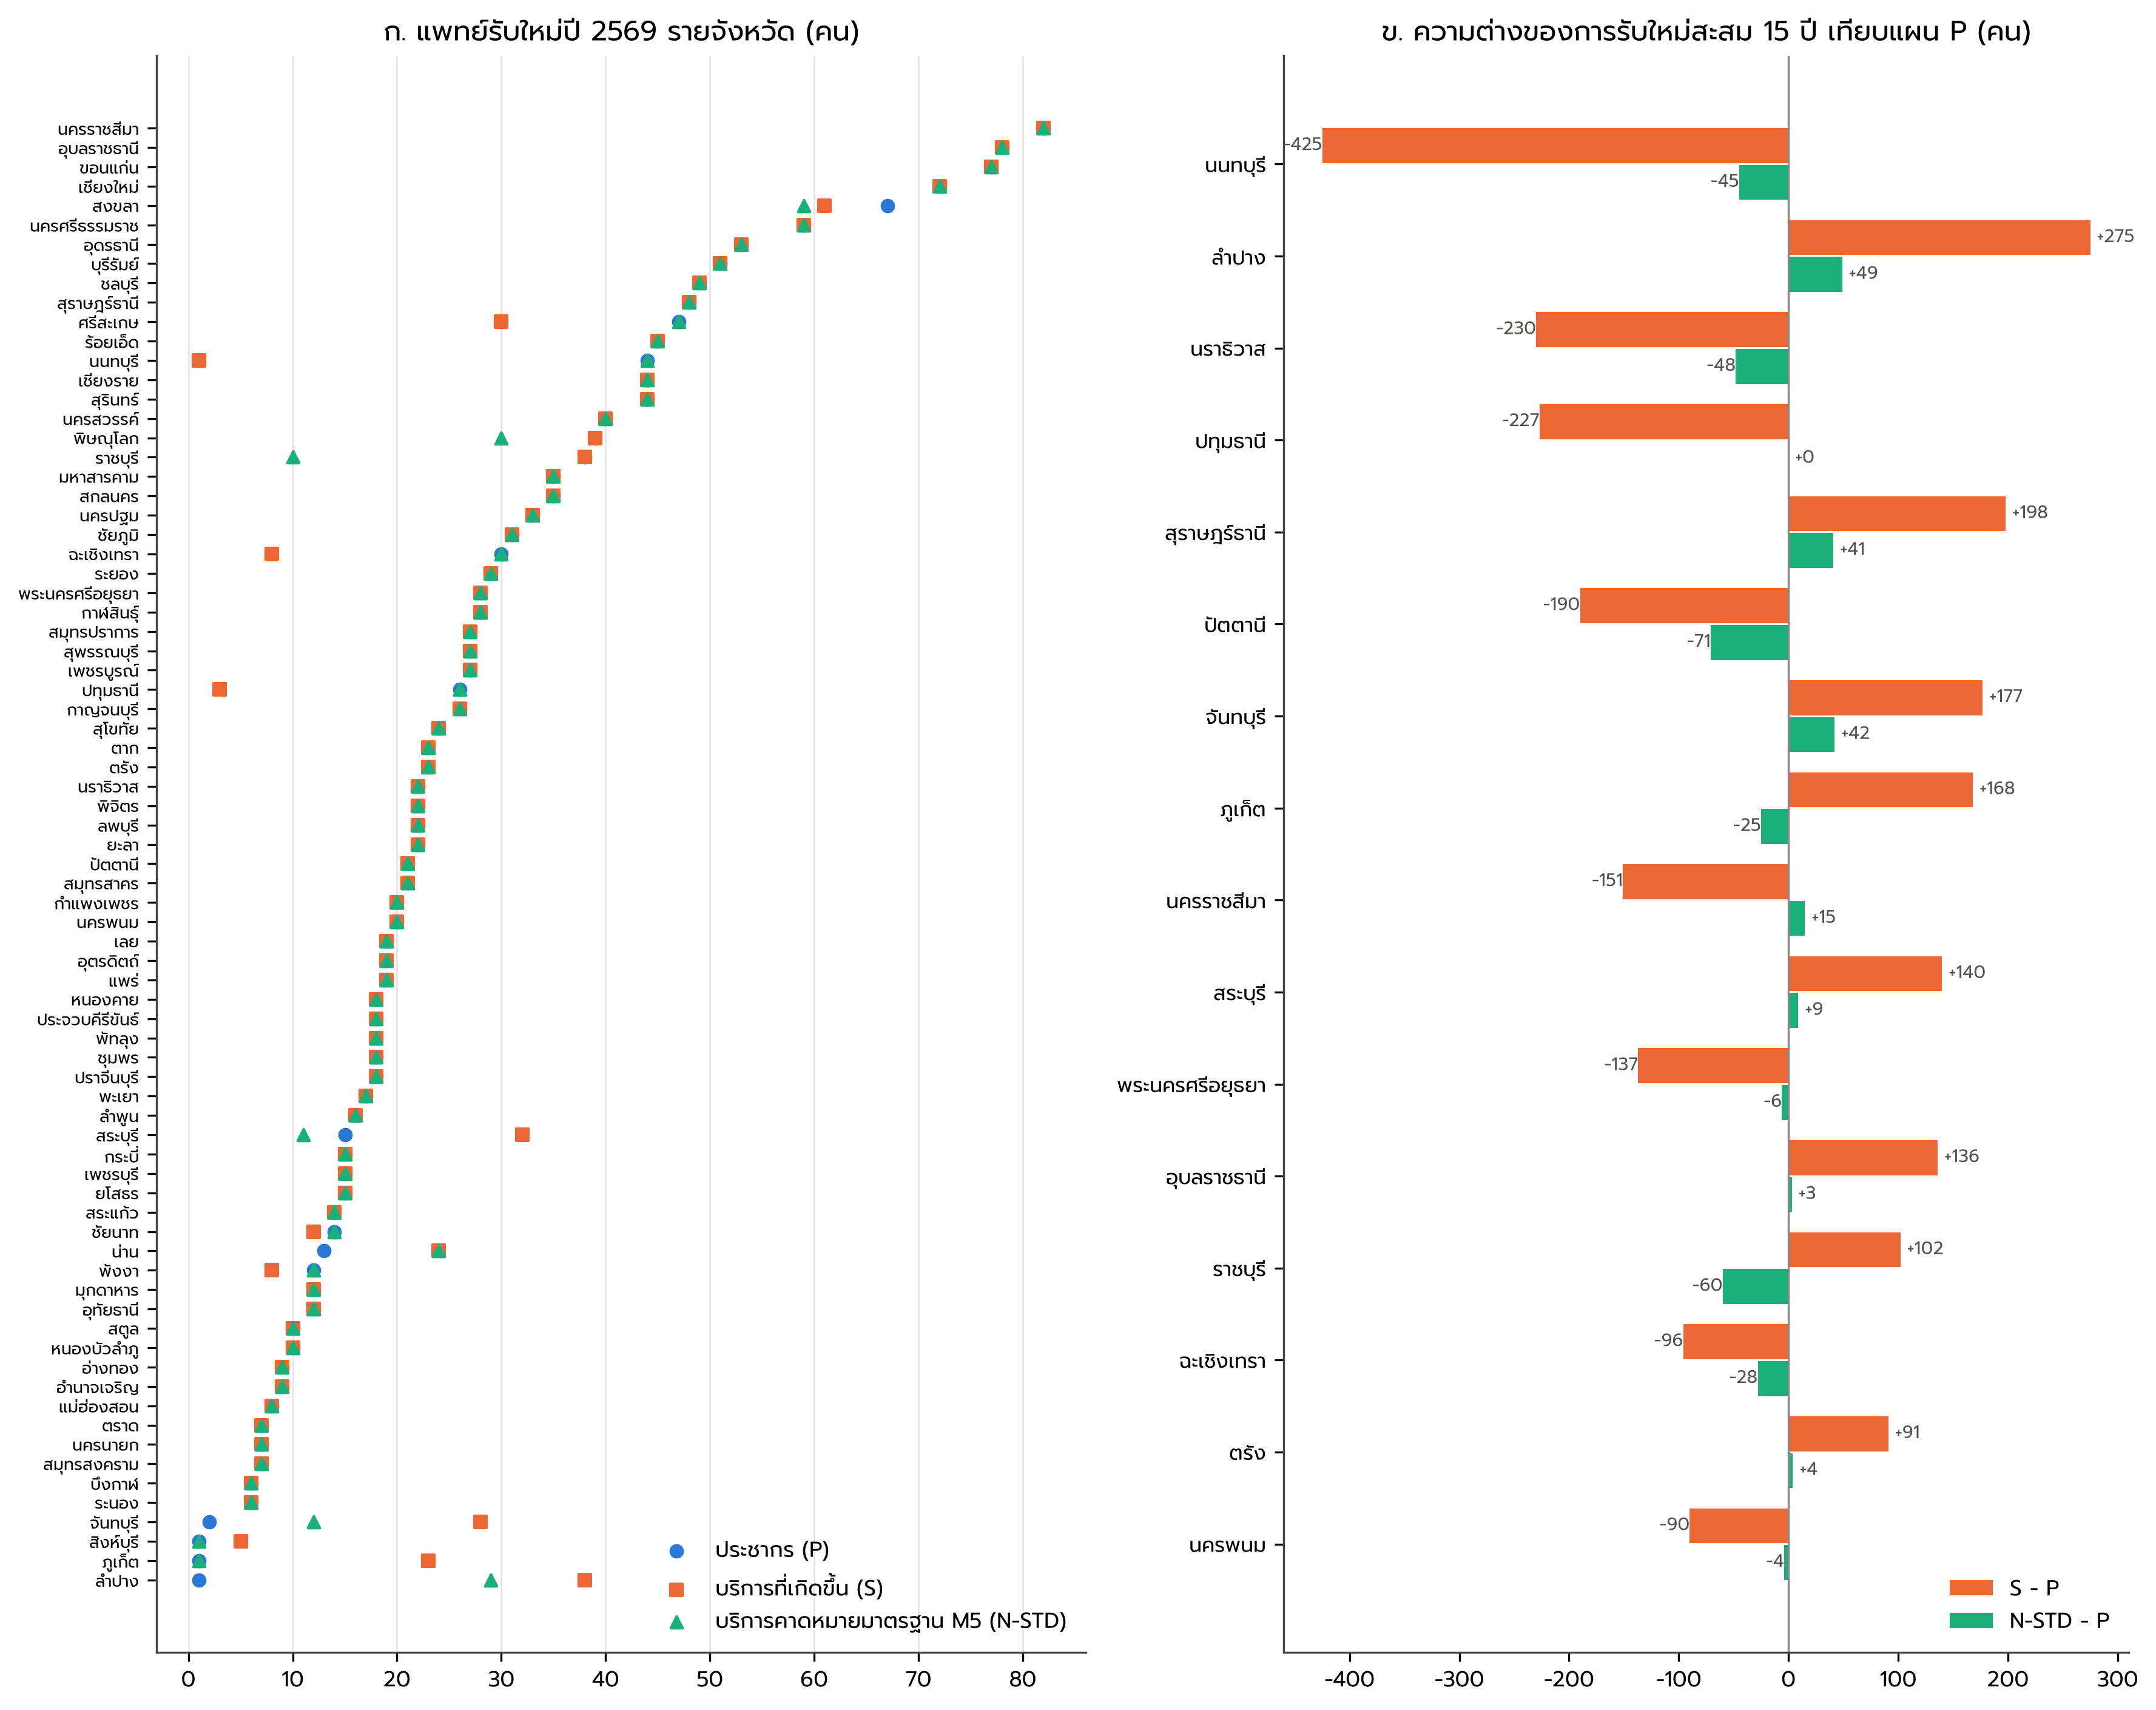

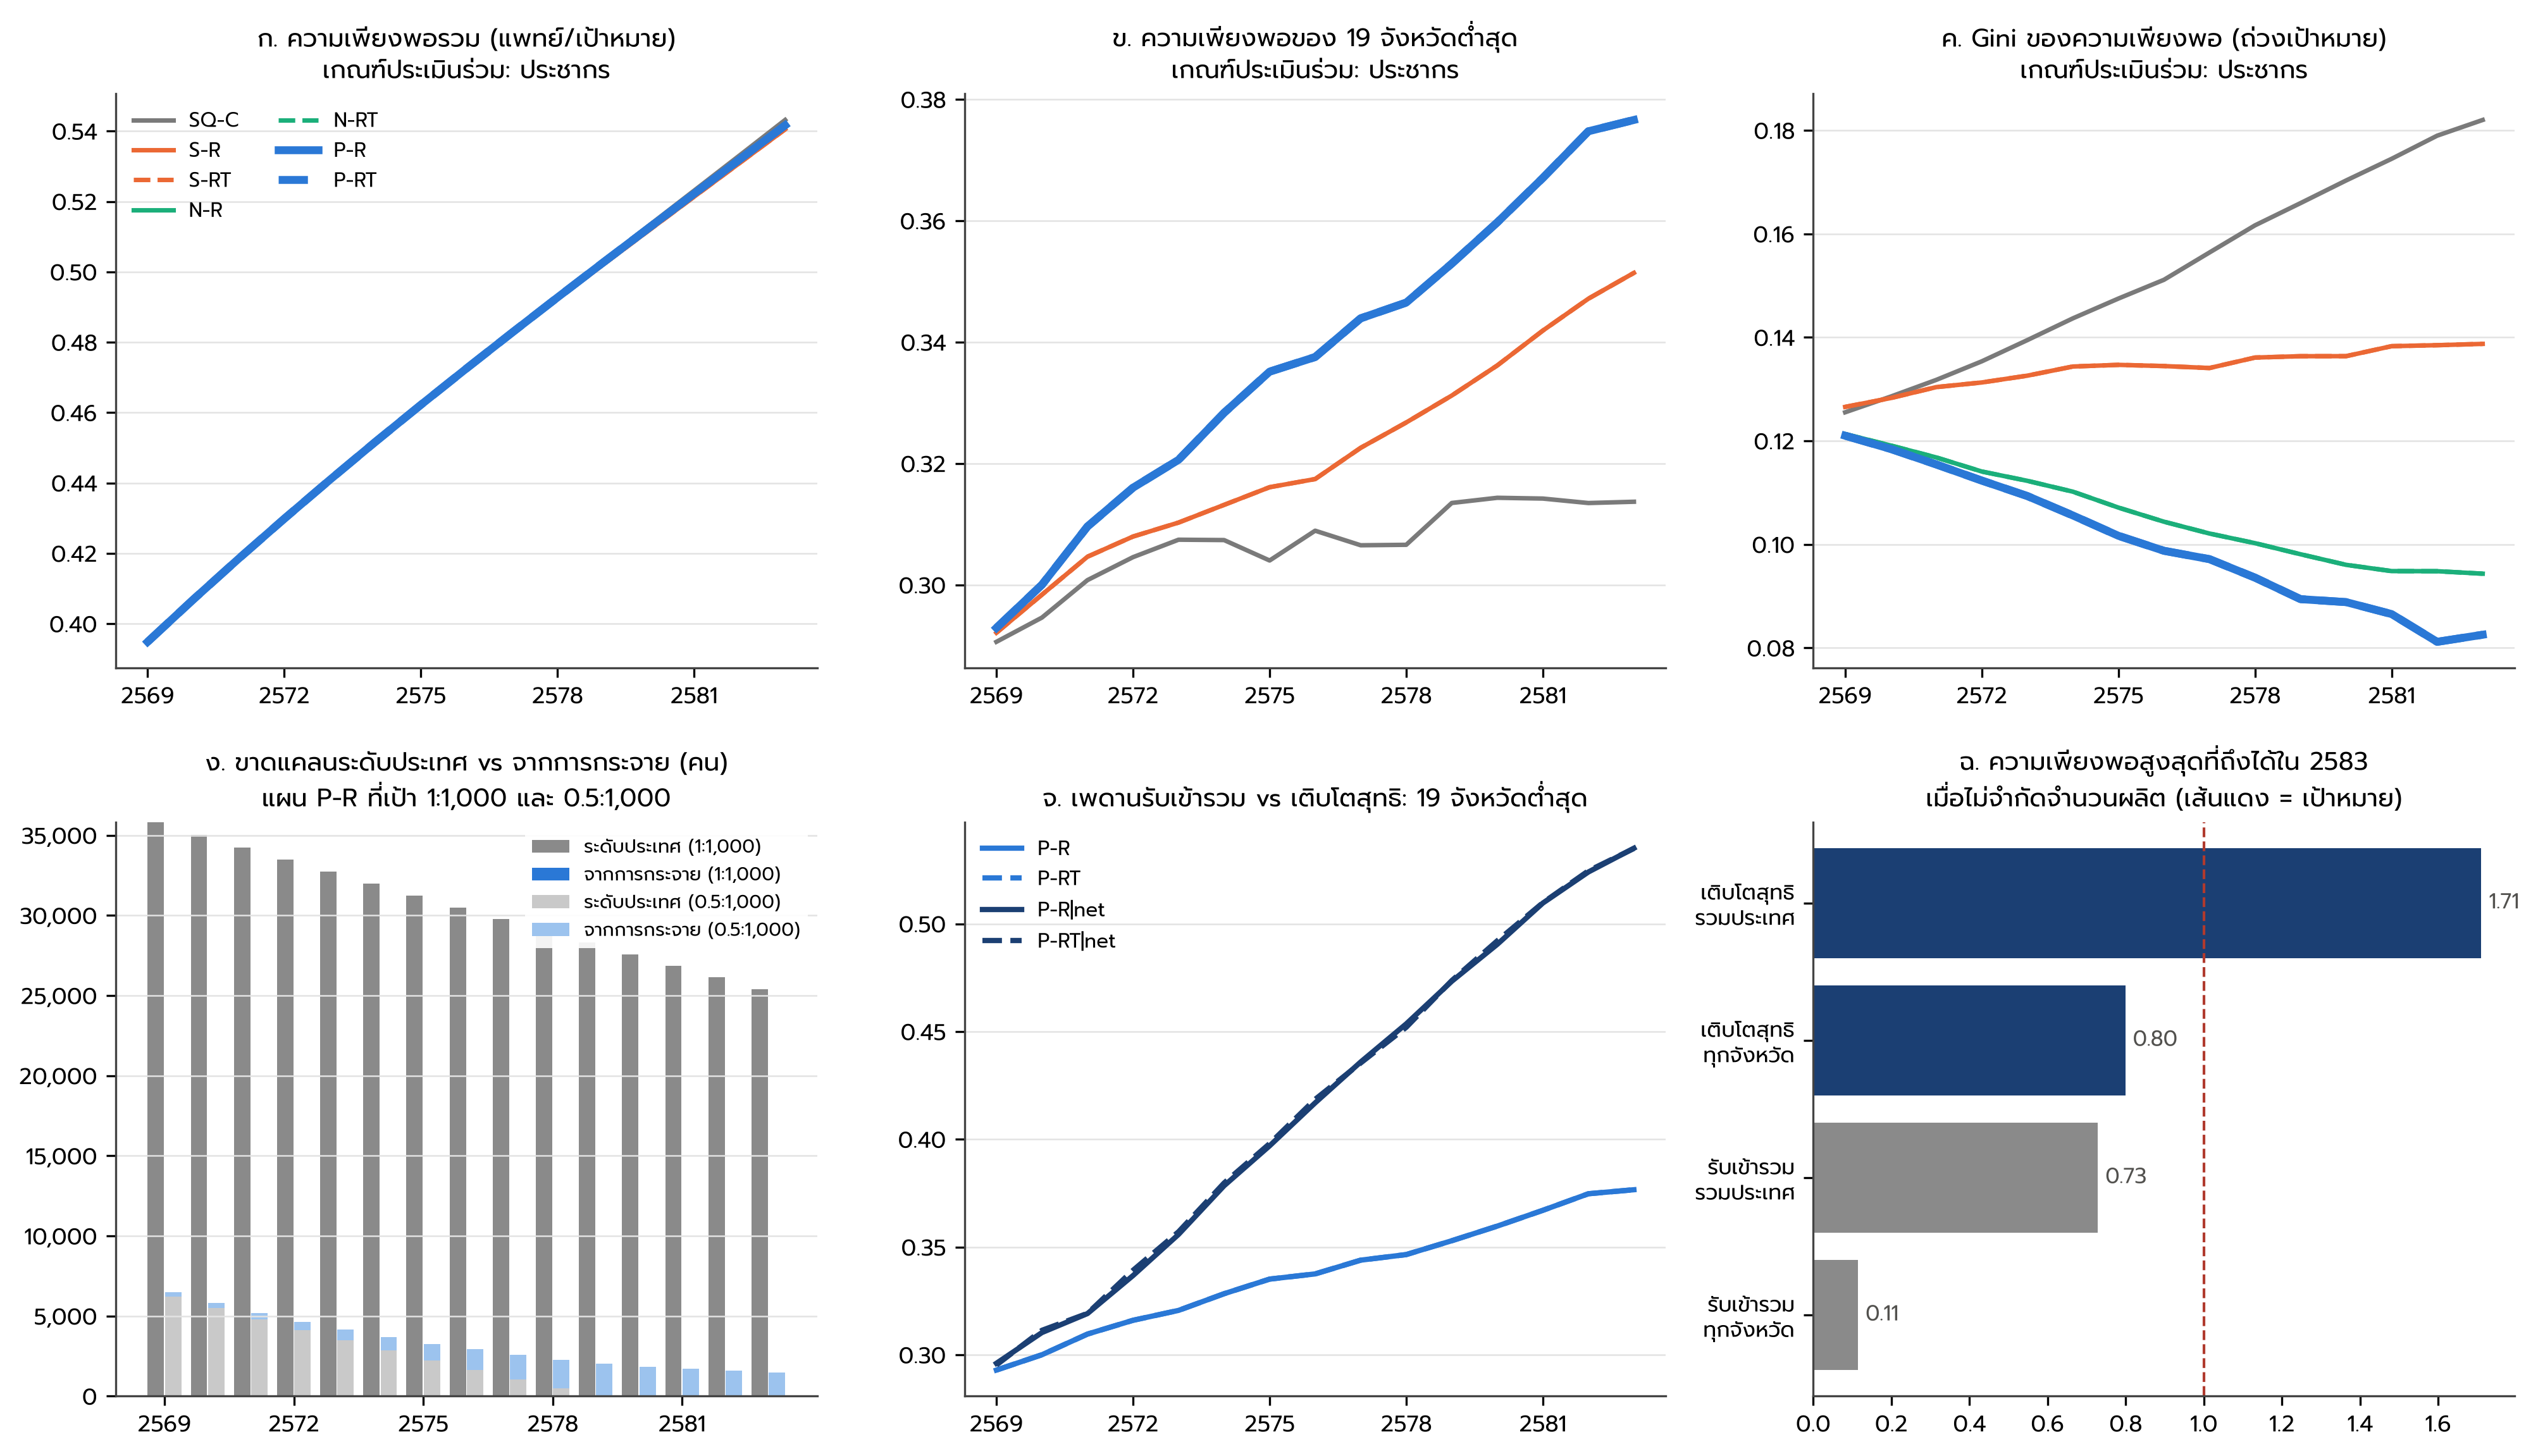

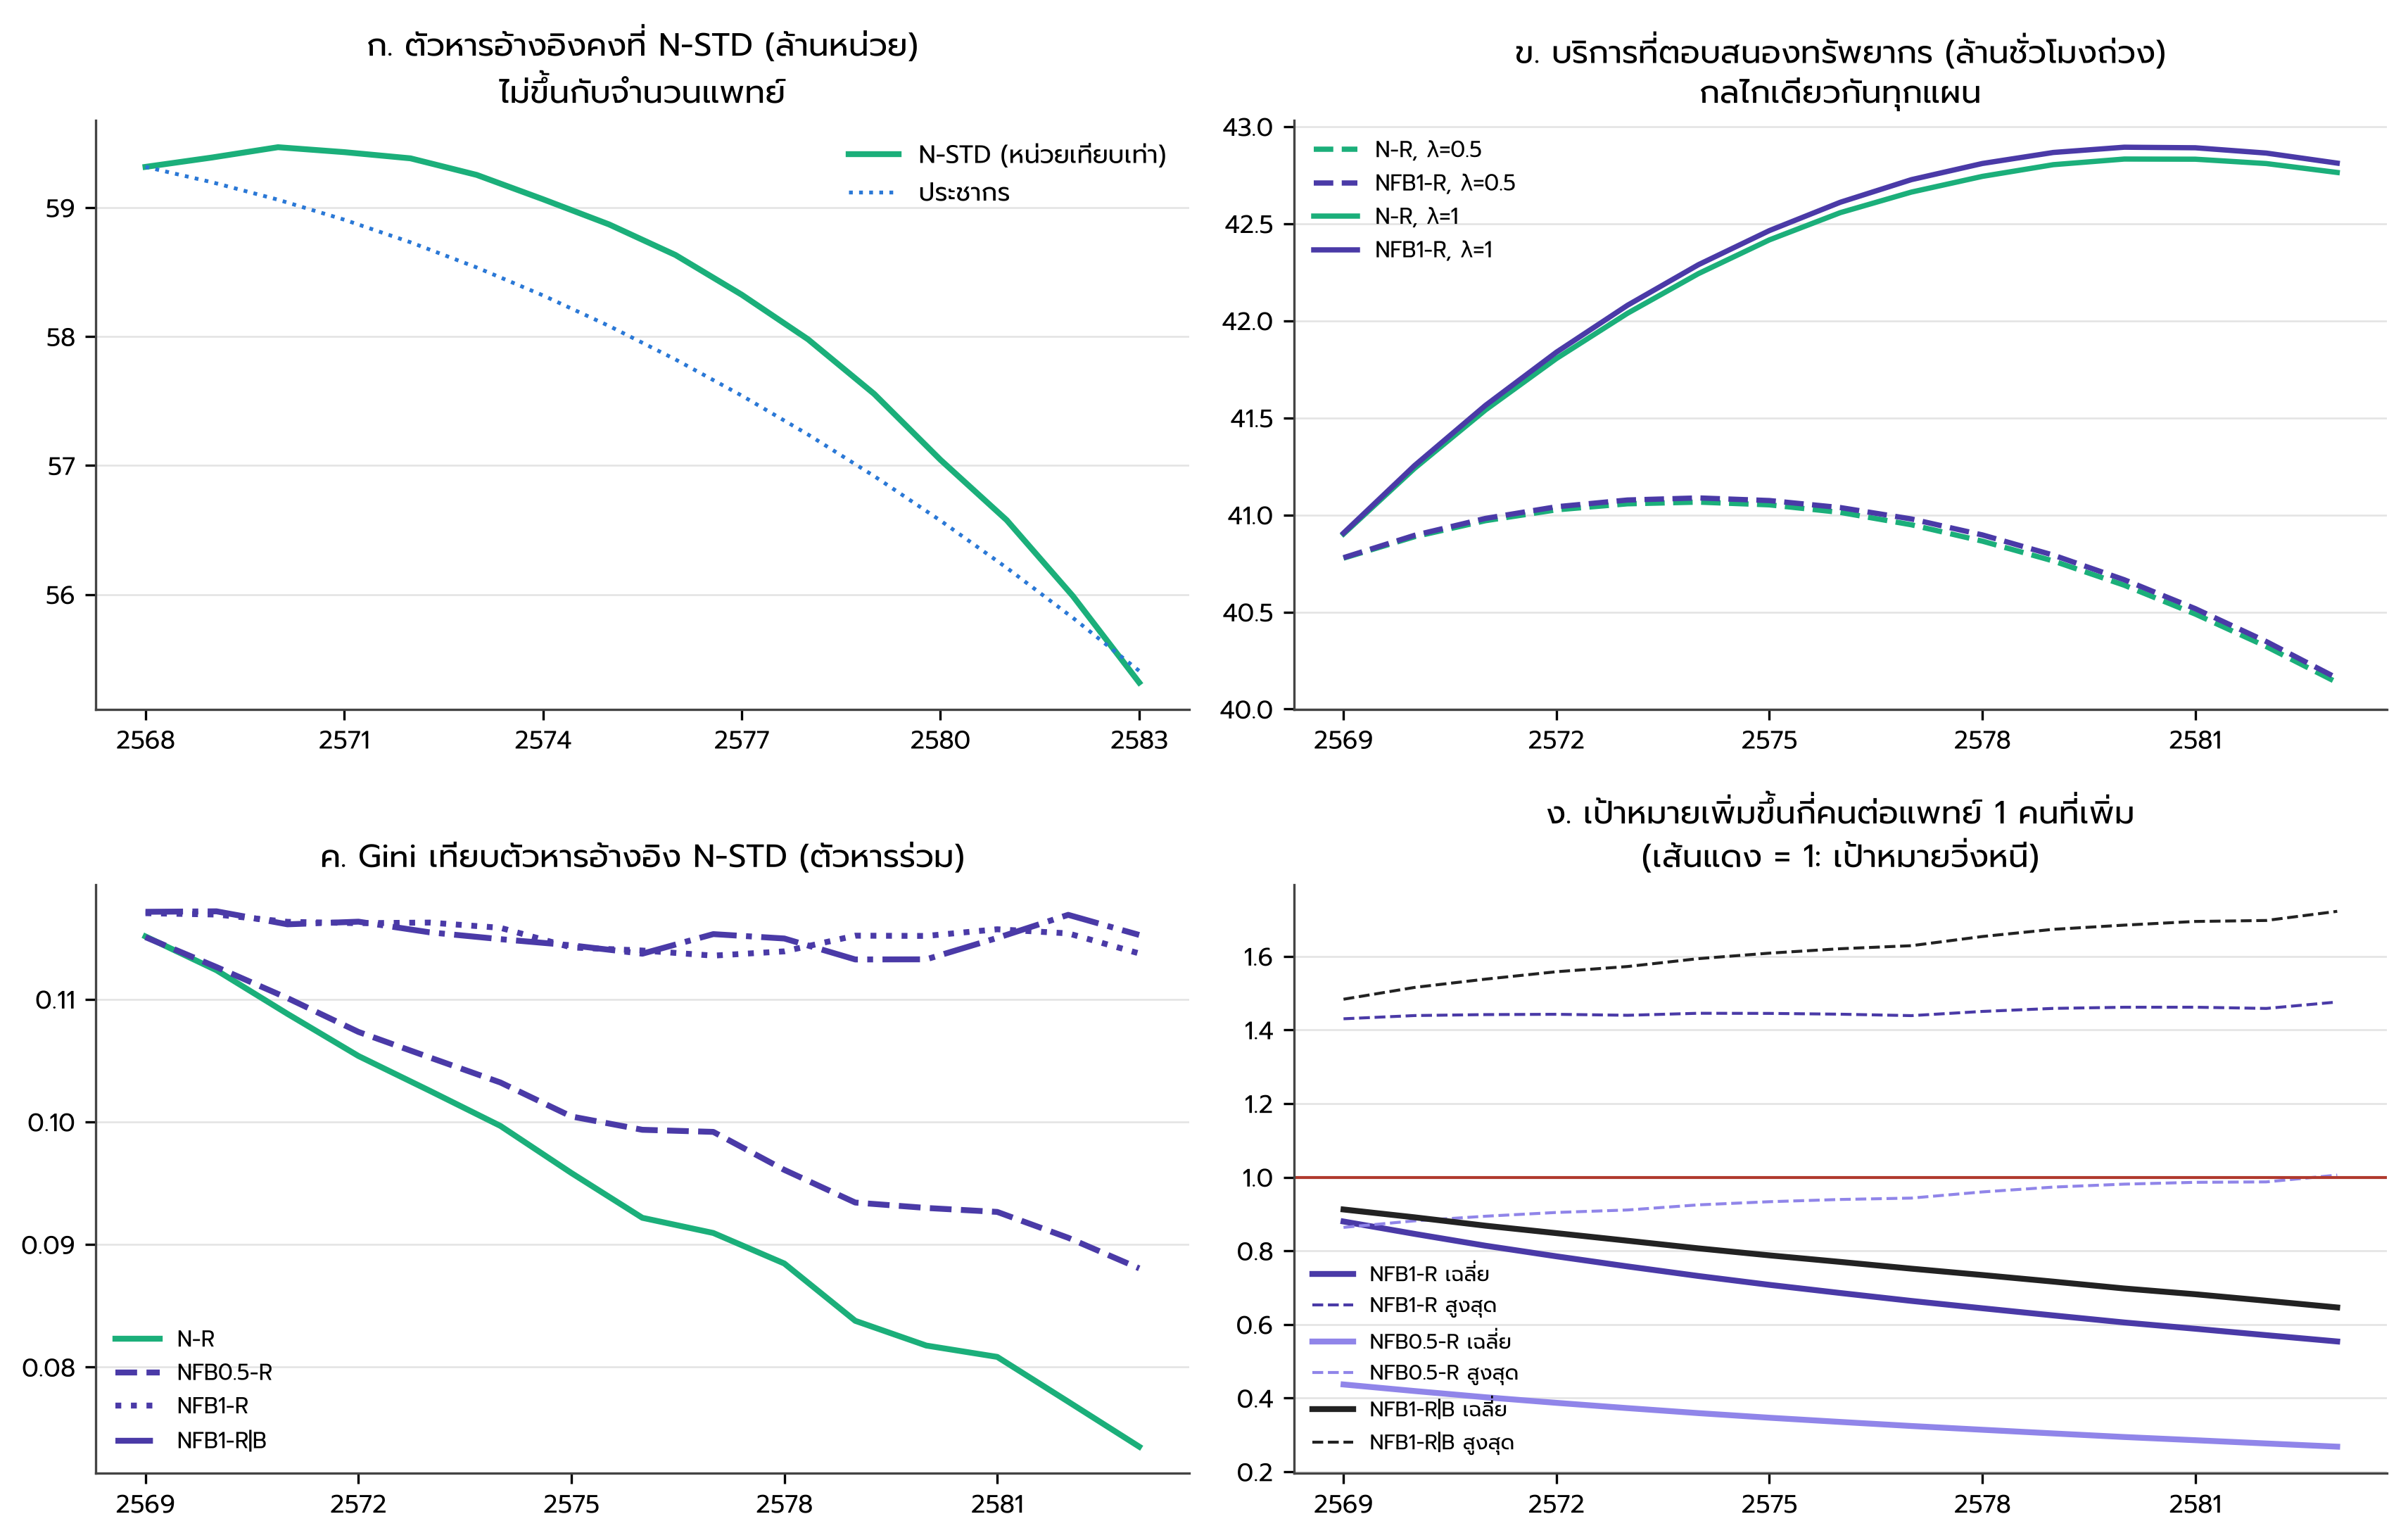

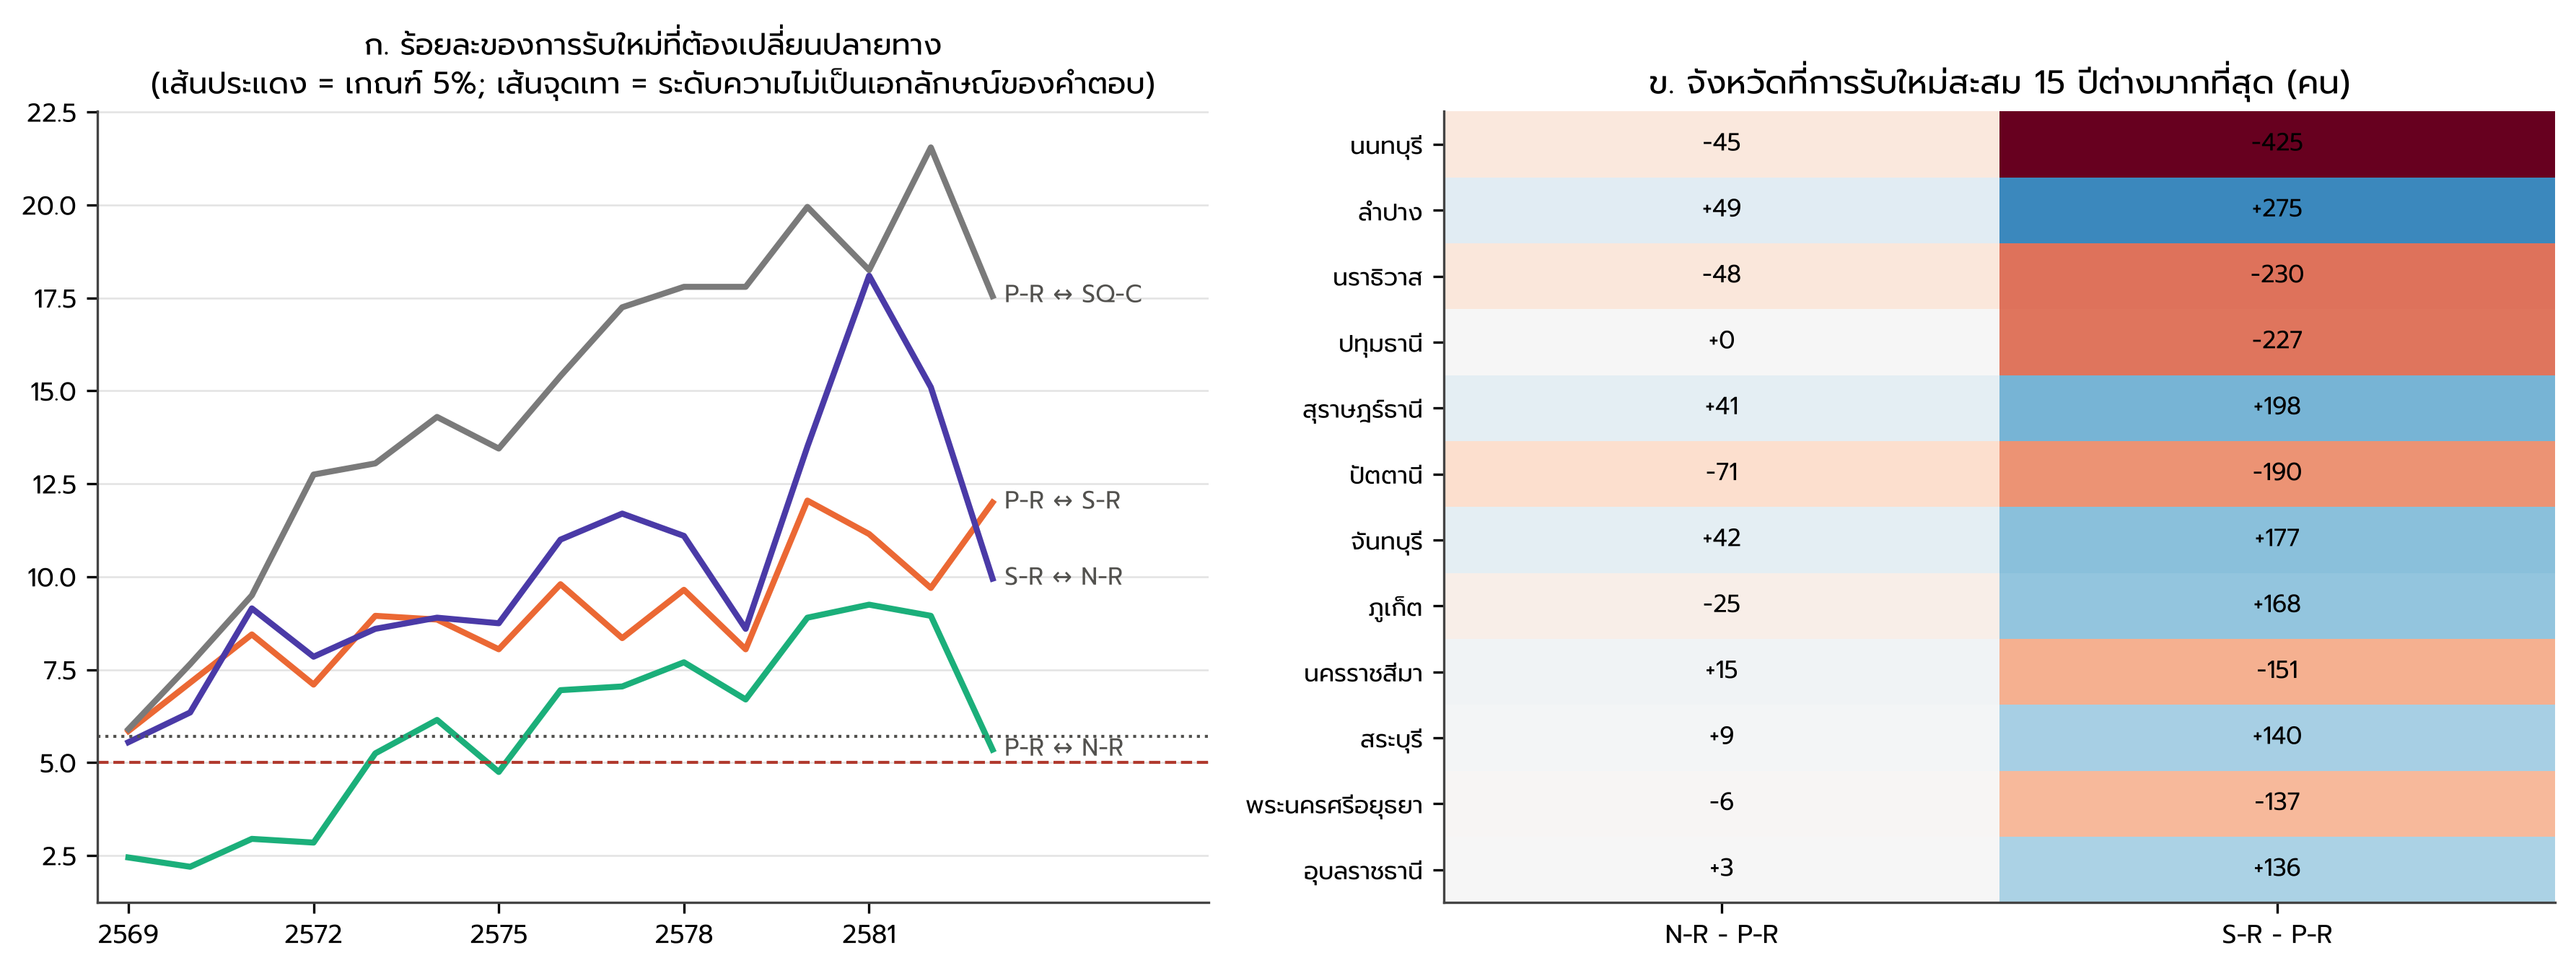

In [5]:
for f in ['F53_ANNUAL_ALLOCATIONS', 'F54_ADEQUACY_AND_INEQUALITY', 'F55_FEEDBACK', 'F56_PLAN_DISAGREEMENT']:
    display(Image(str(D['figures'] / f'{f}.png')))

## ข้อจำกัดที่ตึงตัว การโยกย้าย และความเป็นไปได้ย้อนกลับ

In [6]:
display(tab('T54_TRANSFER_AND_CAPACITY'))
display(tab('T5_INVERSE_FEASIBILITY'))
display(tab('T5_SENSITIVITY_SUMMARY'))

,แผน,เพดาน,สถานะ,การโยกย้ายสะสม (ครั้ง),จังหวัด-ปีที่เพดานตึง (%),จังหวัด-ปีที่ได้เพียงขั้นต่ำ (%),จำนวนที่จัดสรรไม่ได้,J เทียบแผนไม่มีโยกย้าย (%),แพทย์ 2583,จำนวนที่จัดสรรไม่ได้ (ขั้นต่ำ)
0,P-R,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,63.3,1.1,0.0,NaN,30011.0,NaN
1,P-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,63.3,1.1,0.0,0.00,30011.0,NaN
2,S-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,62.1,0.4,0.0,0.00,29948.0,NaN
3,N-RT,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,62.8,1.1,0.0,0.00,30010.0,NaN
4,P-R|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,0.0,10.0,6.0,0.0,NaN,29732.0,NaN
5,P-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,545.0,10.4,6.1,0.0,-0.01,29730.0,NaN
6,S-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,0.0,4.6,2.5,0.0,0.00,29841.0,NaN
7,N-RT|net,เติบโตสุทธิ 10%,exploratory_policy_scenario,298.0,9.5,5.1,0.0,0.02,29742.0,NaN
8,P-RT|tau0.05,รับเข้ารวม 10%,exploratory_policy_scenario,0.0,63.3,1.1,0.0,0.00,30011.0,NaN
9,P-RT|net|tau0.05,เติบโตสุทธิ 10%,exploratory_policy_scenario,2602.0,10.7,8.4,0.0,-0.03,29732.0,NaN


,plan_id,cap_mode,criterion,ramp_limited,ramp_fraction,base_pool,reference_reachable_by_2040,total_appointments_required,pool_2040_required,max_attainment_2040,binding_province,note
0,INV|gross_arrivals,gross_arrivals,province,True,0.1,2000.0,False,NaN,NaN,0.114545,บึงกาฬ,LP relaxation of the recruitment-only problem;...
1,INV|gross_arrivals,gross_arrivals,province,False,NaN,2000.0,False,NaN,NaN,0.114545,บึงกาฬ,LP relaxation of the recruitment-only problem;...
2,INV|gross_arrivals,gross_arrivals,national,True,0.1,2000.0,False,NaN,NaN,0.728660,NaN,LP relaxation of the recruitment-only problem;...
3,INV|gross_arrivals,gross_arrivals,national,False,NaN,2000.0,False,NaN,NaN,0.728660,NaN,LP relaxation of the recruitment-only problem;...
4,INV|net_growth,net_growth,province,True,0.1,2000.0,False,NaN,NaN,0.798970,นนทบุรี,LP relaxation of the recruitment-only problem;...
5,INV|net_growth,net_growth,province,False,NaN,2000.0,False,NaN,NaN,0.798970,ปทุมธานี,LP relaxation of the recruitment-only problem;...
6,INV|net_growth,net_growth,national,True,0.1,2000.0,True,58063.0,6939.0,1.159112,NaN,LP relaxation of the recruitment-only problem;...
7,INV|net_growth,net_growth,national,False,NaN,2000.0,True,56556.0,7588.0,1.710276,NaN,LP relaxation of the recruitment-only problem;...


,plan_id,base_plan,variant,status,stock_2040,national_attainment_own_2040,bottom_quartile_own_2040,gini_own_2040,transfer_events,objective_exact,mean_annual_switch_pct_vs_base,cum_receipts_max_abs_diff_vs_base
0,P-R|pool1500,P-R,pool_1500,exploratory_policy_scenario,24624.170497,0.444425,0.364013,0.043986,0.0,5.205222,NaN,429.0
1,S-R|pool1500,S-R,pool_1500,exploratory_policy_scenario,24776.482428,0.447174,0.390805,0.028904,0.0,5.150291,NaN,394.0
2,N-R|pool1500,N-R,pool_1500,exploratory_policy_scenario,24777.086321,0.447185,0.375413,0.041250,0.0,5.173746,NaN,374.0
3,P-R|net,P-R,net_growth_cap,exploratory_policy_scenario,29731.763185,0.536609,0.535086,0.000905,0.0,4.275106,19.986667,579.0
4,S-R|net,S-R,net_growth_cap,exploratory_policy_scenario,29840.559175,0.538572,0.536264,0.001832,0.0,4.258126,15.583333,200.0
5,N-R|net,N-R,net_growth_cap,exploratory_policy_scenario,29834.825780,0.538469,0.535525,0.003275,0.0,4.269701,21.440000,511.0
6,P-R|depnat,P-R,national_departure_rates,exploratory_policy_scenario,29488.932208,0.532226,0.477875,0.045595,0.0,4.370014,13.706667,168.0
7,P-R|ref0.5,P-R,reference_0.5_per_1000,exploratory_policy_scenario,29842.967264,1.077232,0.753217,0.107065,0.0,0.562403,9.906667,249.0
8,S-R|depnat,S-R,national_departure_rates,exploratory_policy_scenario,29488.932208,0.532226,0.523634,0.006538,0.0,4.321370,13.930000,205.0
9,S-R|ref0.5,S-R,reference_0.5_per_1000,exploratory_policy_scenario,29840.651664,1.077148,0.832181,0.071905,0.0,0.360824,8.293333,139.0


## แผนปีแรก (พ.ศ. 2569)
ตารางเต็ม 15 ปีอยู่ใน `outputs/chapter5/plans/chapter5_annual_allocation_plans.xlsx`

In [7]:
display(tab('T57_FIRST_YEAR_PLAN'))

,จังหวัด,เขต,ตั้งต้น 2568,ออกที่คาด,กลับเข้าที่คาด,รับใหม่ P-R,ปลายปี P-R,ความเพียงพอ P-R,รับใหม่ S-R,ปลายปี S-R,ความเพียงพอ S-R,รับใหม่ N-R,ปลายปี N-R,ความเพียงพอ N-R
0,น่าน,1,252.0,13.8,0.8,13,252.1,0.544,24,263.1,0.487,24,263.1,0.507
1,พะเยา,1,180.0,10.9,0.6,17,186.7,0.420,17,186.7,0.368,17,186.7,0.410
2,ลำปาง,1,399.0,20.0,1.8,1,381.8,0.556,38,418.8,0.394,29,409.8,0.538
3,ลำพูน,1,172.0,11.6,0.7,16,177.1,0.456,16,177.1,0.325,16,177.1,0.421
4,เชียงราย,1,469.0,33.5,2.0,44,481.5,0.417,44,481.5,0.349,44,481.5,0.398
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,ปัตตานี,12,220.0,9.7,0.5,21,231.7,0.311,21,231.7,0.451,21,231.7,0.374
72,พัทลุง,12,190.0,10.7,0.8,18,198.1,0.385,18,198.1,0.323,18,198.1,0.350
73,ยะลา,12,230.0,8.4,0.5,22,244.1,0.440,22,244.1,0.391,22,244.1,0.521
74,สงขลา,12,701.0,29.3,2.3,67,741.1,0.524,61,735.1,0.504,59,733.1,0.538


## เปลี่ยนสมมติฐานแล้วรันใหม่
ตัวอย่าง (เขียนไปยังโฟลเดอร์ฉากทัศน์แยก ไม่ทับผลหลัก):
```
PYTHONPATH=src .venv/bin/python -m chapter5.build --all --set supply.annual_path=2500 --name pool2500
PYTHONPATH=src .venv/bin/python -m chapter5.build --all --set allocation.cap_mode=net_growth --name netcap
```